In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Reproducibility
keras.utils.set_random_seed(42)

print("Keras version:", keras.__version__)
print("NumPy version:", np.__version__)


Keras version: 3.15.1
NumPy version: 2.5.3


In [2]:
#Load Fashion-MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

print("Training images :", x_train.shape)
print("Training labels :", y_train.shape)
print("Test images     :", x_test.shape)
print("Test labels     :", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 1us/step
Training images : (60000, 28, 28)
Training labels : (60000,)
Test images     : (10000, 28, 28)
Test labels     : (10000,)


In [3]:
#Define the class names

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

for i, name in enumerate(class_names):
    print(f"{i}: {name}")


0: T-shirt/top
1: Trouser
2: Pullover
3: Dress
4: Coat
5: Sandal
6: Shirt
7: Sneaker
8: Bag
9: Ankle boot


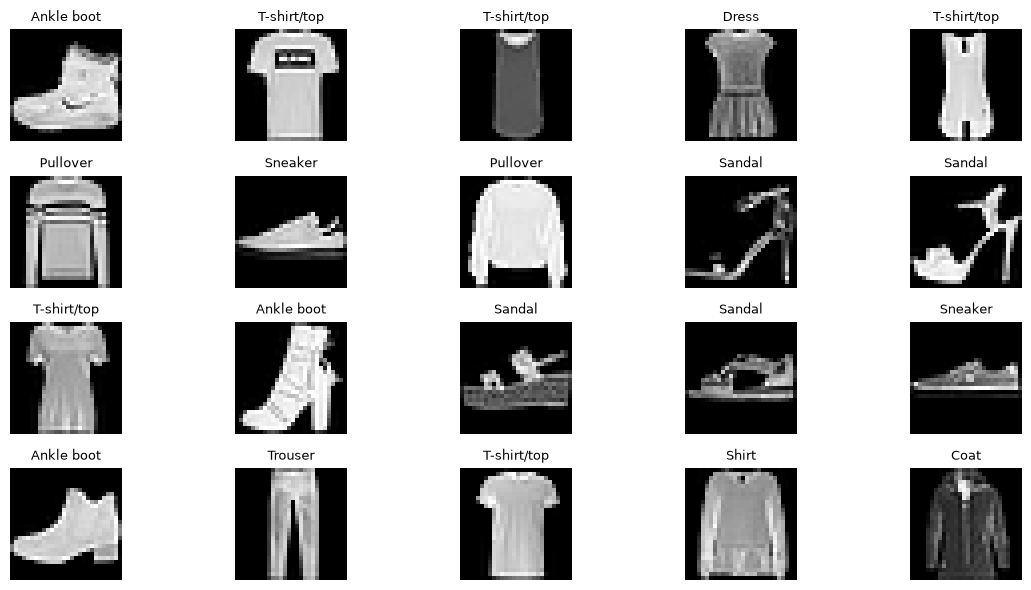

In [4]:
#Visualize sample images

plt.figure(figsize=(12, 6))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


Shape: (28, 28)
Data type: uint8
Minimum pixel: 0
Maximum pixel: 255
Label: 9
Class: Ankle boot


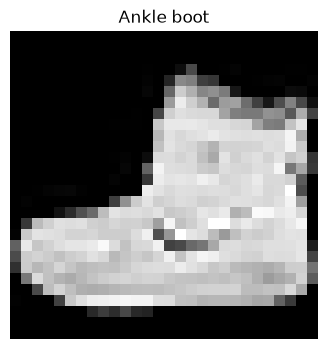

In [5]:
#Inspect one image

index = 0

print("Shape:", x_train[index].shape)
print("Data type:", x_train[index].dtype)
print("Minimum pixel:", x_train[index].min())
print("Maximum pixel:", x_train[index].max())
print("Label:", y_train[index])
print("Class:", class_names[y_train[index]])

plt.figure(figsize=(4, 4))
plt.imshow(x_train[index], cmap="gray")
plt.title(class_names[y_train[index]])
plt.axis("off")
plt.show()


In [6]:
#Normalize the images

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training range:", x_train.min(), "to", x_train.max())
print("Test range    :", x_test.min(), "to", x_test.max())


Training range: 0.0 to 1.0
Test range    : 0.0 to 1.0


In [7]:
#Create a smaller classroom dataset

# Use 10,000 training images as our classroom pool.
x_pool = x_train[:10_000]
y_pool = y_train[:10_000]


# Split the pool into 8,000 training and 2,000 validation images.
x_train_cnn, x_val_cnn, y_train_cnn, y_val_cnn = train_test_split(
    x_pool,
    y_pool,
    test_size=0.20,
    random_state=42,
    stratify=y_pool,
)

# Select 2,000 balanced examples from the original test set.
x_test_cnn, _, y_test_cnn, _ = train_test_split(
    x_test,
    y_test,
    train_size = 2000,
    random_state=42,
    stratify=y_test,
)

print("Training set  :", x_train_cnn.shape, y_train_cnn.shape)
print("Validation set:", x_val_cnn.shape, y_val_cnn.shape)
print("Test set      :", x_test_cnn.shape, y_test_cnn.shape)


Training set  : (8000, 28, 28) (8000,)
Validation set: (2000, 28, 28) (2000,)
Test set      : (2000, 28, 28) (2000,)


In [8]:
#Add the channel dimension

a = np.array([1, 2, 3])
print(a.shape)
a1 = a[:, np.newaxis]
print(a1.shape)
# np.newaxis = "Please create one extra dimension here."

(3,)
(3, 1)


In [9]:
x_train_cnn = x_train_cnn[..., np.newaxis]
x_val_cnn = x_val_cnn[..., np.newaxis]
x_test_cnn = x_test_cnn[..., np.newaxis]

print("Training shape  :", x_train_cnn.shape)
print("Validation shape:", x_val_cnn.shape)
print("Test shape      :", x_test_cnn.shape)


Training shape  : (8000, 28, 28, 1)
Validation shape: (2000, 28, 28, 1)
Test shape      : (2000, 28, 28, 1)


In [10]:
# Small numerical example: one convolution calculation

image_patch = np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1],
], dtype=float)

example_filter = np.array([
    [1, 1, 1],
    [0, 0, 0],
    [-1, -1, -1],
], dtype=float)

product = image_patch * example_filter
result = np.sum(product)

print("Image patch:")
print(image_patch)

print("\nFilter:")
print(example_filter)

print("\nElement-wise product:")
print(product)

print("\nOne convolution result:", result)


Image patch:
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]

Filter:
[[ 1.  1.  1.]
 [ 0.  0.  0.]
 [-1. -1. -1.]]

Element-wise product:
[[ 1.  1.  1.]
 [ 0.  0.  0.]
 [-1. -1. -1.]]

One convolution result: 0.0


In [11]:
#Create the CNN

cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # First convolution block
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification head
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
#Check the tensor shapes with one batch

sample_batch = x_train_cnn[:4]

# A forward pass through the untrained CNN.
sample_output = cnn_model(sample_batch)

print("Input batch shape :", sample_batch.shape)
print("Output batch shape:", sample_output.shape)
print("Each image produces 10 class probabilities.")


Input batch shape : (4, 28, 28, 1)
Output batch shape: (4, 10)
Each image produces 10 class probabilities.


In [13]:
#Compile the CNN

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("CNN compiled successfully!")


CNN compiled successfully!


In [14]:
#Train the CNN

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train_cnn,
    validation_data=(x_val_cnn, y_val_cnn),
    epochs=10,
    batch_size=64,
    verbose=1,
)


Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.6957 - loss: 0.8303 - val_accuracy: 0.8080 - val_loss: 0.5172
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.8271 - loss: 0.4684 - val_accuracy: 0.8280 - val_loss: 0.4642
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.8568 - loss: 0.3983 - val_accuracy: 0.8340 - val_loss: 0.4490
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8716 - loss: 0.3576 - val_accuracy: 0.8510 - val_loss: 0.4118
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.8830 - loss: 0.3228 - val_accuracy: 0.8705 - val_loss: 0.3690
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.8923 - loss: 0.2952 - val_accuracy: 0.8765 - val_loss: 0.3518
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.9016 - loss: 0.2715 - val_accuracy: 0.8810 - val_loss: 0.3385
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.9087 - loss: 0.2503 - val_accu

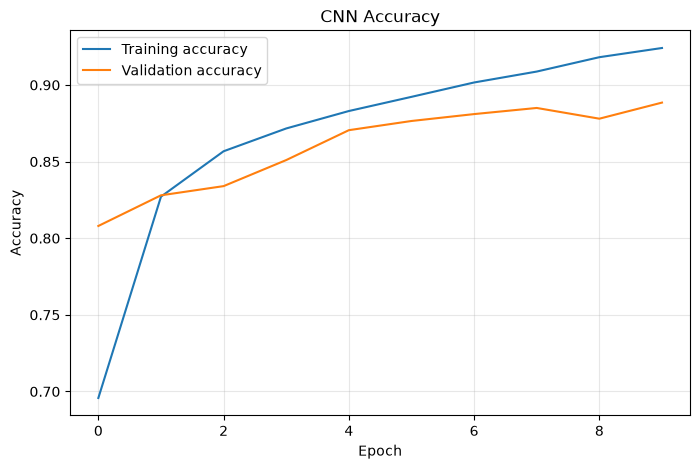

In [15]:
#Plot training vs validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    cnn_history.history["accuracy"],
    label="Training accuracy",
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="Validation accuracy",
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


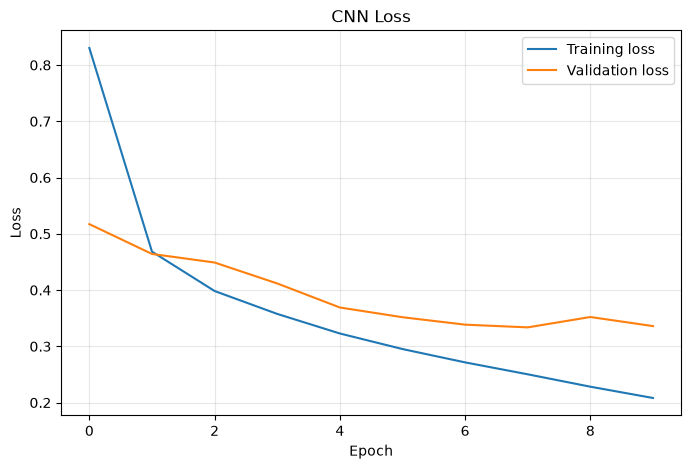

In [16]:
#Plot training vs validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    cnn_history.history["loss"],
    label="Training loss",
)

plt.plot(
    cnn_history.history["val_loss"],
    label="Validation loss",
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [17]:
#Evaluate the CNN

test_loss, test_accuracy = cnn_model.evaluate(
    x_test_cnn,
    y_test_cnn,
    verbose=0,
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Test accuracy : {test_accuracy * 100:.2f}%")


Test loss     : 0.3597
Test accuracy : 0.8845
Test accuracy : 88.45%


In [18]:
#Predict class probabilities

y_prob = cnn_model.predict(
    x_test_cnn,
    verbose=0,
)

y_pred = np.argmax(y_prob, axis=1)

print("Actual labels   :", y_test_cnn[:20])
print("Predicted labels:", y_pred[:20])


Actual labels   : [4 9 4 4 9 0 1 1 5 4 4 9 3 0 5 9 4 9 4 5]
Predicted labels: [4 9 4 4 9 0 1 1 5 2 4 9 3 0 5 9 4 9 4 5]


In [19]:
# Verify prediction accuracy with sklearn

accuracy = accuracy_score(y_test_cnn, y_pred)

print(f"Accuracy from predictions: {accuracy:.4f}")
print(f"Accuracy from predictions: {accuracy * 100:.2f}%")


Accuracy from predictions: 0.8845
Accuracy from predictions: 88.45%


Confusion matrix shape: (10, 10)


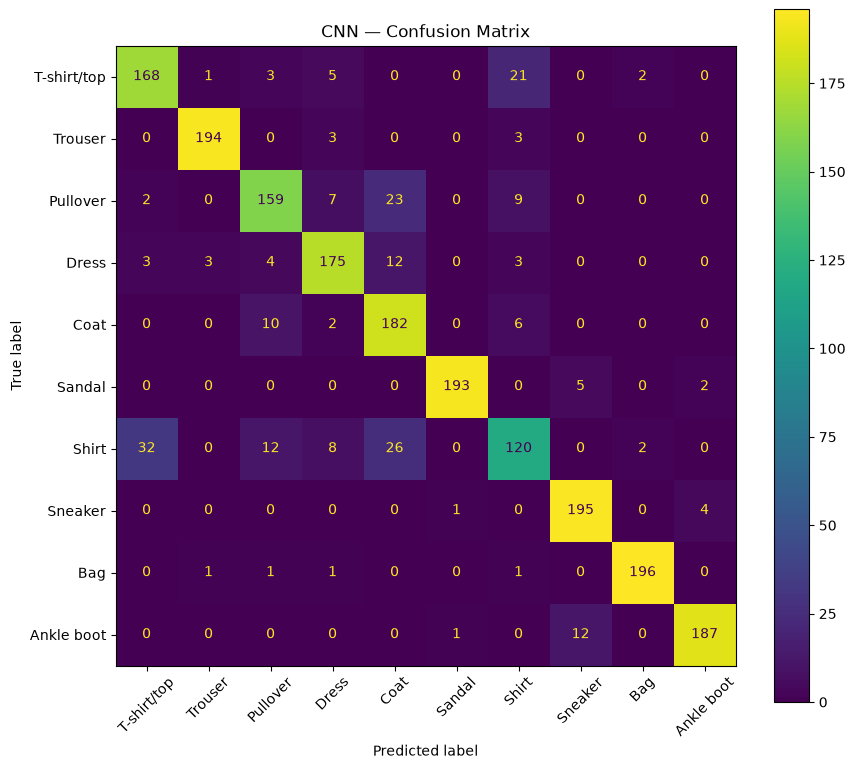

In [20]:
#Confusion matrix

cm = confusion_matrix(y_test_cnn, y_pred)

print("Confusion matrix shape:", cm.shape)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
)

fig, ax = plt.subplots(figsize=(10, 9))
disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
)

plt.title("CNN — Confusion Matrix")
plt.show()


In [21]:
#Classification report

print(
    classification_report(
        y_test_cnn,
        y_pred,
        target_names=class_names,
        zero_division=0,
    )
)


              precision    recall  f1-score   support

 T-shirt/top       0.82      0.84      0.83       200
     Trouser       0.97      0.97      0.97       200
    Pullover       0.84      0.80      0.82       200
       Dress       0.87      0.88      0.87       200
        Coat       0.75      0.91      0.82       200
      Sandal       0.99      0.96      0.98       200
       Shirt       0.74      0.60      0.66       200
     Sneaker       0.92      0.97      0.95       200
         Bag       0.98      0.98      0.98       200
  Ankle boot       0.97      0.94      0.95       200

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



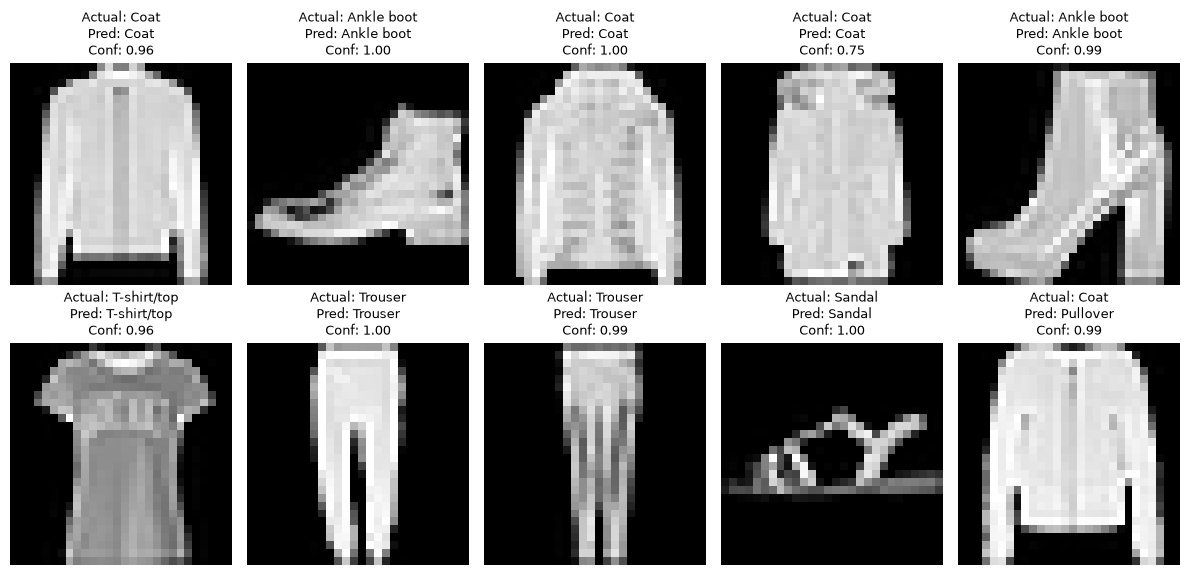

In [22]:
#See actual vs predicted classes

n_show = 10

fig, axes = plt.subplots(
    2,
    5,
    figsize=(12, 6),
)

axes = axes.ravel()

for i in range(n_show):
    axes[i].imshow(x_test_cnn[i].squeeze(), cmap="gray")

    actual = class_names[y_test_cnn[i]]
    predicted = class_names[y_pred[i]]
    confidence = y_prob[i, y_pred[i]]

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"Conf: {confidence:.2f}",
        fontsize=9,
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [23]:
#Inspect one prediction in detail

i = 0

print("Actual class   :", class_names[y_test_cnn[i]])
print("Predicted class:", class_names[y_pred[i]])
print(f"Confidence     : {y_prob[i, y_pred[i]]:.2%}")

probability_table = pd.DataFrame({
    "Class": class_names,
    "Probability": y_prob[i],
})

probability_table["Probability (%)"] = (
    probability_table["Probability"] * 100
)

# Sort from highest to lowest probability
probability_table = (
    probability_table
    .sort_values("Probability", ascending=False)
    .reset_index(drop=True)
)

# Display in a classroom-friendly format instead of scientific notation
display(
    probability_table.style
    .format({
        "Probability": "{:.4f}",
        "Probability (%)": "{:.2f}%"
    })
    .hide(axis="index")
)



Actual class   : Coat
Predicted class: Coat
Confidence     : 96.18%


Class,Probability,Probability (%)
Coat,0.9618,96.18%
Pullover,0.0359,3.59%
Shirt,0.0022,0.22%
Ankle boot,0.0000,0.00%
Bag,0.0000,0.00%
T-shirt/top,0.0000,0.00%
Dress,0.0000,0.00%
Trouser,0.0000,0.00%
Sandal,0.0000,0.00%
Sneaker,0.0000,0.00%
